# Demo Ridge: feature → validation → dự báo

Chạy Ridge qua các cell quan sát được. Thuật toán và quy tắc chọn dùng lại source/config; không dùng dữ liệu test cho scaler hoặc chọn siêu tham số.

Chạy từ trên xuống bằng **Restart Kernel → Run All**, hoặc Shift+Enter từng cell. Thuật toán dùng lại từ `source/`; không sửa các CSV nghiên cứu đã có. Xem `notebooks/README.md` để cấu hình đường dẫn/kernel.

## Đường dẫn và môi trường
Kiểm tra các đường dẫn trước khi chạy. Các notebook độc lập: mặc định đọc clean/preparation đã lưu; không yêu cầu chạy notebook trước để có biến trong RAM.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p/'source/preprocessing').is_dir() and (p/'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the repository root or notebooks directory.')
for folder in [PROJECT_ROOT, PROJECT_ROOT/'notebooks', PROJECT_ROOT/'source/preprocessing']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from demo_support import (configure, show_paths, demo_directory, save_table, save_json,
                          show_source, show_png, environment, compare_values, read_series, series_plot)
PATHS = configure(PROJECT_ROOT)
# Nếu cần, sửa PATHS.population_raw / history_raw / population_clean / history_clean / preparation tại đây.
show_paths(PATHS)
print('Python kernel:', sys.executable)


,setting,path,exists
0,project,D:\Phân tích kinh doanh_2627\GitHub\IS403.R14....,True
1,data_root,D:\Phân tích kinh doanh_2627,True
2,population_raw,D:\Phân tích kinh doanh_2627\archive\Electric_...,True
3,history_raw,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
4,population_clean,D:\Phân tích kinh doanh_2627\archive\EV_Popula...,True
5,history_clean,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
6,preparation,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True
7,output_root,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True


Python kernel: c:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe


In [2]:
OUT = demo_directory(PATHS, 'ridge')
print('Output demo:', OUT)
display(environment())


Output demo: D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\notebook_demo\ridge_20261116_040715_383a641b


,package,version,status
0,pandas,3.0.5,Đã tìm thấy
1,numpy,2.5.3,Đã tìm thấy
2,scipy,1.18.1,Đã tìm thấy
3,matplotlib,3.11.2,Đã tìm thấy
4,statsmodels,0.15.0,Đã tìm thấy
5,scikit-learn,1.9.1,Đã tìm thấy
6,xgboost,3.4.1,Đã tìm thấy
7,ipykernel,7.3.0,Đã tìm thấy


## Chuỗi, train/test và cấu hình
Xem trước cấu hình và quy tắc chọn. Default chạy lại toàn bộ grid; không hard-code ID đã chọn.

In [3]:
from source.forecasting import features
from source.forecasting.models import ml, ridge as model
from source.forecasting.backtest import run_cross_validation
from source.forecasting.run_ml_forecast import summarize_candidates, forecast_frame
from source.forecasting.metrics import calculate_metrics
series = read_series(PATHS)
train = series.loc[series['split'].eq('train')].copy()
test = series.loc[series['split'].eq('test')].copy()
spec = json.loads((PROJECT_ROOT/'source/forecasting/configs/ridge.json').read_text(encoding='utf-8'))
display(pd.DataFrame(spec['candidates']))
print(spec['selection'])
show_source(model.fit)


,config_id,alpha
0,RIDGE01,0.1
1,RIDGE02,1.0
2,RIDGE03,10.0


Within 1% of minimum mean validation RMSE, prefer larger alpha; then mean RMSE and config_id.


def fit(history, config):
    return ml.fit(history, config, Ridge(alpha=config['alpha'], solver='svd'), scale_x=True)

## Tạo 5 feature từ quá khứ
Mẫu đầu ở tháng thứ 8. Full train 64 mẫu; ba prefix CV 40/46/52. Nhãn và rolling không chứa tương lai.

In [5]:
growth = features.compute_log_growth(train.ev_total)
X,y,names = features.build_supervised_dataset(growth)
supervised = pd.DataFrame(X, columns=names)
supervised.insert(0,'date',train.date.iloc[7:].to_numpy())
supervised['target_log_growth'] = y
display(supervised.head(8))
display(pd.DataFrame([{'train_months':n,'supervised_rows':len(features.build_supervised_dataset(features.compute_log_growth(train.ev_total.iloc[:n]))[1])}
                      for n in [47,53,59,71]]))
assert X.shape==(64,5)
# Căn chỉ số mẫu đầu: label r[7], đầu vào chỉ từ r[1:7].
expected_first = [growth[6],growth[5],growth[4],np.mean(growth[4:7]),np.mean(growth[1:7])]
compare_values('First-row past-only alignment',X[0],expected_first)


,date,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,target_log_growth
0,2017-08-31,0.022424,0.026505,0.025329,0.024753,0.026623,0.019365
1,2017-09-30,0.019365,0.022424,0.026505,0.022765,0.024767,0.023766
2,2017-10-31,0.023766,0.019365,0.022424,0.021852,0.024394,0.026138
3,2017-11-30,0.026138,0.023766,0.019365,0.023090,0.023921,0.020837
4,2017-12-31,0.020837,0.026138,0.023766,0.023580,0.023172,0.018834
5,2018-01-31,0.018834,0.020837,0.026138,0.021936,0.021894,0.032639
6,2018-02-28,0.032639,0.018834,0.020837,0.024103,0.023597,0.017998
7,2018-03-31,0.017998,0.032639,0.018834,0.023157,0.023369,0.024730


,train_months,supervised_rows
0,47,40
1,53,46
2,59,52
3,71,64


,check,passed,max_absolute_difference
0,First-row past-only alignment,True,0.0


## Validation chỉ trong train
True tính CV mới; False đọc lại bảng đã lưu và ghi rõ chế độ. Scaler của từng lượt fit nằm trong prefix.

In [6]:
RUN_GRID_SEARCH = True
if RUN_GRID_SEARCH:
    runs = [run_cross_validation(series,model.fit,model.forecast,config,return_forecasts=True) for config in spec['candidates']]
    cv = pd.concat([result[0] for result in runs],ignore_index=True)
    validation_forecasts = pd.concat([result[1] for result in runs],ignore_index=True)
    print('Validation recomputed from train prefixes.')
else:
    cv = pd.read_csv(PROJECT_ROOT/'results/forecasting/cv_ridge.csv')
    validation_forecasts = pd.read_csv(PROJECT_ROOT/'results/forecasting/validation_forecasts_ridge.csv')
    print('Showing saved validation; grid was NOT rerun in this cell.')
cv['n_supervised'] = cv['n_train_months'] - 7
display(cv[['config_id','fold','origin','rmse','status','warnings']])
scores, selected = summarize_candidates(cv,spec)
display(scores)
print('Locked config before test:',selected)


Validation recomputed from train prefixes.


,config_id,fold,origin,rmse,status,warnings
0,RIDGE01,1,2020-11-30,1143.636972,ok,[]
1,RIDGE01,2,2021-05-31,748.256332,ok,[]
2,RIDGE01,3,2021-11-30,593.361040,ok,[]
3,RIDGE02,1,2020-11-30,1148.670964,ok,[]
4,RIDGE02,2,2021-05-31,747.667120,ok,[]
5,RIDGE02,3,2021-11-30,592.556772,ok,[]
6,RIDGE03,1,2020-11-30,1116.603701,ok,[]
7,RIDGE03,2,2021-05-31,739.860987,ok,[]
8,RIDGE03,3,2021-11-30,590.916420,ok,[]


,config_id,alpha,eligible,selected,mean_rmse,mean_mae,mean_smape,mean_bias,within_tolerance
0,RIDGE01,0.1,True,False,828.418115,689.025486,0.813811,502.646687,False
1,RIDGE02,1.0,True,False,829.631618,690.394282,0.815549,501.401103,False
2,RIDGE03,10.0,True,True,815.793703,682.517785,0.805042,474.590960,True


Locked config before test: {'config_id': 'RIDGE03', 'alpha': 10.0}


## Minh họa scaler ở một prefix
Dùng fold 1 để nhìn thấy số mẫu và thống kê được fit từ prefix, không từ 83 tháng.

In [7]:
prefix = train.iloc[:47].copy()
fold_artifact = model.fit(prefix,selected)
X_fold,y_fold,_ = features.build_supervised_dataset(features.compute_log_growth(prefix.ev_total))
fold_info = ml.describe(fold_artifact)
display(pd.DataFrame([{'n_prefix_months':47,'n_supervised':fold_info['n_supervised'],
                       'target_mean':fold_info['target_mean'],'target_scale':fold_info['target_scale'],
                       'x_standardized':fold_info['x_standardized']}]))
compare_values('Prefix target scaler mean/std',[fold_info['target_mean'],fold_info['target_scale']],
               [y_fold.mean(),y_fold.std(ddof=0)])
if fold_artifact['x_scaler'] is not None:
    display(pd.DataFrame(fold_artifact['x_scaler'].transform(X_fold),columns=names).head())
else:
    display(pd.DataFrame(X_fold,columns=names).head())
    print('RF/XGBoost giữ nguyên X; chỉ nhãn tăng trưởng được chuẩn hóa.')


,n_prefix_months,n_supervised,target_mean,target_scale,x_standardized
0,47,40,0.022748,0.010272,True


,check,passed,max_absolute_difference
0,Prefix target scaler mean/std,True,0.0


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6
0,-0.027060,0.355290,0.212748,0.249318,0.530967
1,-0.324895,-0.041716,0.328507,-0.019321,0.229822
2,0.103622,-0.339249,-0.073334,-0.142699,0.169264
3,0.334587,0.088834,-0.374491,0.024585,0.092529
4,-0.181624,0.319564,0.058806,0.090858,-0.028974


## Fit cấu hình đã khóa trên full train
64 mẫu học. Xem estimator, scaler, warning và cỡ mô hình thực tế.

In [8]:
artifact = model.fit(train,selected)
assert artifact['converged'] is not False
fitted_info = ml.describe(artifact)
display(artifact['estimator'])
display(pd.DataFrame([fitted_info]))
if artifact['x_scaler'] is not None:
    display(pd.DataFrame(artifact['x_scaler'].transform(X),columns=names).head())
display(pd.DataFrame({'target_r':y,'standardized_z':artifact['y_scaler'].transform(y.reshape(-1,1)).ravel()}).head())


,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10.0
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'svd'
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

,n_supervised,feature_names,x_standardized,x_mean,x_scale,target_mean,...,target_variance,scaler_ddof,converged,warnings,coefficients,intercept
0,64,"[r_lag_1, r_lag_2, r_lag_3, r_mean_3, r_mean_6]",True,"[0.023069589577328686, 0.022966458974048753, 0...","[0.008676142576108522, 0.00859508671488483, 0....",0.023211,...,0.000076,0,None,[],"[0.10993402304366985, -0.07289110436057196, 0....",[-1.541956996901841e-16]


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6
0,-0.074413,0.411698,0.259427,0.285751,0.693795
1,-0.426935,-0.063116,0.396817,-0.047566,0.326649
2,0.080264,-0.418963,-0.080111,-0.200648,0.252819
3,0.353636,0.093020,-0.437543,0.006912,0.159265
4,-0.257357,0.368970,0.076720,0.089140,0.011133


,target_r,standardized_z
0,0.019365,-0.440100
1,0.023766,0.063505
2,0.026138,0.334941
3,0.020837,-0.271724
4,0.018834,-0.500871


## Xem một bước dự báo và đổi ngược scaler
Tại gốc, đầu vào chỉ có tăng trưởng lịch sử. Không kẹp r âm về 0.

In [9]:
row = features.extract_features_at_step(growth)
z_one,r_one = ml.predict_growth(artifact,row)
level_one = float(train.ev_total.iloc[-1]*np.exp(r_one))
display(pd.DataFrame([dict(zip(names,row),z_pred=z_one,r_pred=r_one,pred=level_one)]))


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,z_pred,r_pred,pred
0,0.031478,0.033105,0.016176,0.02692,0.026017,-0.040715,0.022855,115559.18516


## Dự báo đệ quy 12 bước và trace
Bước 2 dùng r_pred bước 1; actual test chỉ ghép vào sau khi sinh đủ 12 dự báo.

,check,passed,max_absolute_difference
0,Step 2 lag uses predicted growth,True,0.0


,date,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,z_pred,r_pred,horizon,pred
0,2022-12-31,0.031478,0.033105,0.016176,0.026920,0.026017,-0.040715,0.022855,1,115559.185160
1,2023-01-31,0.022855,0.031478,0.033105,0.029146,0.026188,0.353257,0.026298,2,118638.453270
2,2023-02-28,0.026298,0.022855,0.031478,0.026877,0.026033,0.378127,0.026515,3,121826.245899
3,2023-03-31,0.026515,0.026298,0.022855,0.025223,0.026071,0.093171,0.024025,4,124788.587460
4,2023-04-30,0.024025,0.026515,0.026298,0.025613,0.027379,0.174744,0.024738,5,127914.105092
5,2023-05-31,0.024738,0.024025,0.026515,0.025093,0.025985,0.181316,0.024795,6,131125.436596
6,2023-06-30,0.024795,0.024738,0.024025,0.024520,0.024871,0.084548,0.023950,7,134303.778548
7,2023-07-31,0.023950,0.024795,0.024738,0.024494,0.025054,0.093772,0.024030,8,137570.248018
8,2023-08-31,0.024030,0.023950,0.024795,0.024259,0.024676,0.093551,0.024029,9,140915.891050
9,2023-09-30,0.024029,0.024030,0.023950,0.024003,0.024261,0.060035,0.023736,10,144300.631497


,date,actual,pred
0,2022-12-31,115665.0,115559.185160
1,2023-01-31,119377.0,118638.453270
2,2023-02-28,122322.0,121826.245899
3,2023-03-31,125478.0,124788.587460
4,2023-04-30,129728.0,127914.105092
5,2023-05-31,133975.0,131125.436596
6,2023-06-30,138353.0,134303.778548
7,2023-07-31,142537.0,137570.248018
8,2023-08-31,148730.0,140915.891050
9,2023-09-30,152690.0,144300.631497


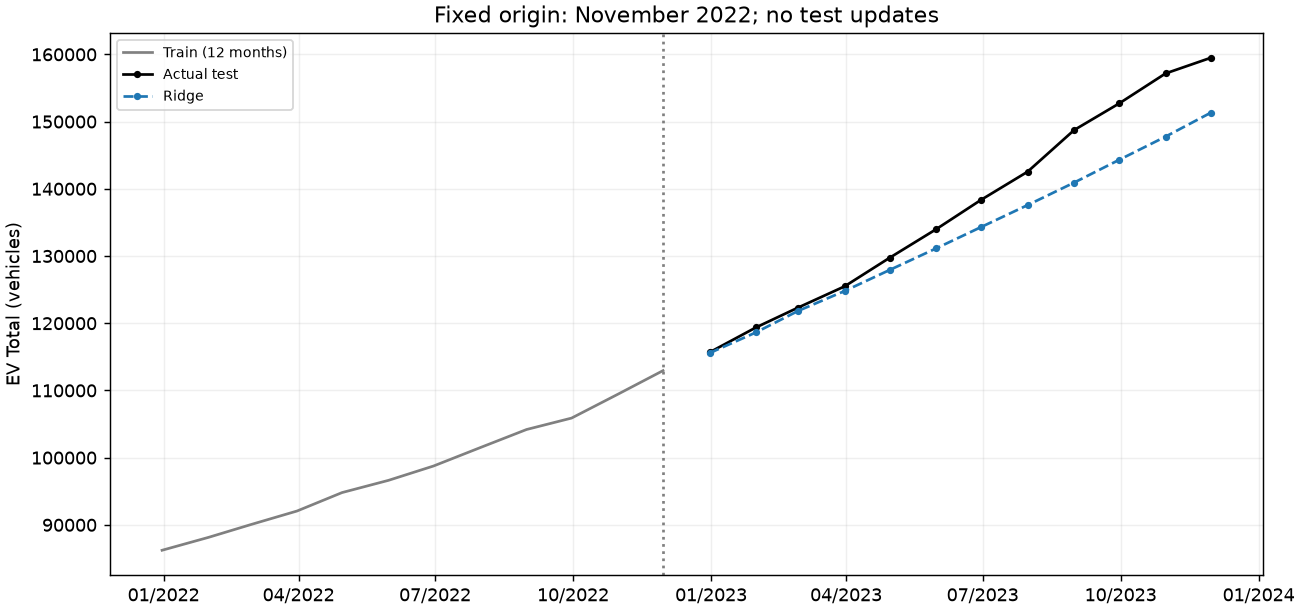

In [10]:
pred, rows = ml.forecast_with_trace(artifact,train,12)
trace = pd.DataFrame(rows)
trace.insert(0,'date',test.date.dt.strftime('%Y-%m-%d').to_numpy())
compare_values('Step 2 lag uses predicted growth',trace.loc[1,'r_lag_1'],trace.loc[0,'r_pred'])
forecast = forecast_frame('ridge',selected['config_id'],test,pred)
display(trace)
display(forecast[['date','actual','pred']])
series_plot(train,test,{'Ridge':pred})


## Chấm điểm và đối chiếu dự báo
Không dùng test để chọn lại config. Khoảng dự báo ML chưa được ước lượng, giữ trống.

In [11]:
metric = calculate_metrics(test.ev_total,pred)
display(pd.DataFrame([dict(model='Ridge',**metric)]))
reference = pd.read_csv(PROJECT_ROOT/'results/forecasting/forecast_ridge.csv')
compare_values('Ridge forecast vs published result',pred,reference.pred)
assert forecast[['lower_95','upper_95','interval_level']].isna().all().all()
save_table(forecast,OUT/'forecast_ridge.csv')
save_table(trace,OUT/'trace_ridge.csv')
save_table(scores,OUT/'candidate_scores_ridge.csv')
save_table(cv,OUT/'cv_ridge.csv')
save_table(validation_forecasts,OUT/'validation_forecasts_ridge.csv')
save_json({'config':selected,'fit':fitted_info,'test_metrics':metric},OUT/'demo_fit.json')


,model,rmse,mae,smape,bias
0,Ridge,5325.824073,4123.900879,2.851233,4123.900879


,check,passed,max_absolute_difference
0,Ridge forecast vs published result,True,1.455192e-11


## Giới hạn diễn giải
Một gốc test 12 tháng không chứng minh ưu thế dài hạn. Các fold CV chồng lấn, không coi là mẫu độc lập. Nếu môi trường/dữ liệu đổi và kết quả lệch, giữ kết quả thật và kiểm tra nguyên nhân; không sửa số cho giống bảng cũ.